# Progetto Super Resolution

L'obiettivo del progetto è addestrare una rete che prende in input immagini a bassa risoluzione e ne migliora la qualità

Verrà usato il dataset DIV2K; Da ogni immagine ad alta risoluzione (HR) verrà estratta una patch per addestrare la rete.

In fase di training le immagini vengono ritagliate in n patch casuali, nella fase di validazione si usano le immagini intere

In [1]:
import torch

import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

from torchvision import transforms

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(device)

DIV2K_TRAIN_HR_DIR = "../dataset/DIV2K_train_HR"
DIV2K_VALID_HR_DIR = "../dataset/DIV2K_valid_HR"

DIV2K_TRAIN_LR_BICUB_2X = "../dataset/DIV2K_train_LR_bicubic/X2"
DIV2K_VALID_LR_BICUB_2X = "../dataset/DIV2K_valid_LR_bicubic/X2"

DATASET_TRAIN_STR: str = "train"
DATASET_VALIDATION_STR: str = "validation"

DW_SCALE: int = 2

LEARNING_RATE = 0.0001
EPOCHS = 450

import torch
print(torch.cuda.is_available())
print(torch.version.hip)       # deve mostrare la versione ROCm
print(torch.version.cuda)      # probabilmente None

cuda
True
7.2.53211
None


# Classe per gestire i dataset

In [2]:
import os
import random
from torch.utils.data import DataLoader, Dataset
from pathlib import Path
from PIL import Image

class DIV2KDataset(Dataset):
    # hr_dir e lr_dir sono le directory per i due dataset
    # scale, è il downscaling factor
    # patch_per_img, quante patch per ogni immagine
    # patch_size, quanto è grande una patch che verrà estratta
    
    def __init__(self, hr_dir, lr_dir, mode=DATASET_TRAIN_STR, scale=DW_SCALE, patches_per_img=20, patch_size=64):
        super().__init__()

        self.scale = scale
        self.patches_per_img = patches_per_img
        self.patch_size = patch_size
        self.mode = mode

        # Carico i path per ogni immagine HR e LR
        self.hr_paths = sorted(Path(hr_dir).glob("*.png"))
        self.lr_paths = sorted(Path(lr_dir).glob("*.png"))

        self.lr_patches = []
        self.hr_patches = []
        
        # Oggetto per convertire dati in tensori
        self.to_tensor = transforms.ToTensor()

        if self.mode == DATASET_TRAIN_STR:
            self._build_patches()
        else:
            self.lr_imgs = [Image.open(p).convert('RGB') for p in self.lr_paths]
            self.hr_imgs = [Image.open(p).convert('RGB') for p in self.hr_paths]

    # Restituisce il numero di campioni
    # in fase di training avrò n_campioni = n_img * patch_per_img
    # in fase di test e validazione avrò n_campioni = n_img
    def __len__(self):
        if self.mode == DATASET_TRAIN_STR:
            return len(self.hr_patches)
        else:
            return len(self.hr_imgs)
        
    def __getitem__(self, idx):
        if self.mode == DATASET_TRAIN_STR:
            return self.lr_patches[idx], self.hr_patches[idx]

        # LR già in RAM, HR caricata dal disco on-demand
        lr = self.lr_imgs[idx]
        hr = self.hr_imgs[idx]
             
        lr_tensor = self.to_tensor(lr)
        hr_tensor = self.to_tensor(hr)

        return lr_tensor, hr_tensor
    
    def _build_patches(self):
        self.lr_imgs = [Image.open(p).convert('RGB') for p in self.lr_paths]
        self.hr_imgs = [Image.open(p).convert('RGB') for p in self.hr_paths]

        for hr, lr in  zip(self.lr_imgs, self.hr_imgs):

            w, h = hr.size

            for _ in range(self.patches_per_img):
                x_cord: int = random.randint(0, w - self.patch_size)
                y_cord: int = random.randint(0, h - self.patch_size)

                # tengo conto dello scaling factor per le immagini LR
                x_cord_scaled: int = x_cord // self.scale
                y_cord_scaled: int = y_cord // self.scale

                patch_size_scaled = self.patch_size // self.scale

                # Ritaglio le patch
                hr_patch = hr.crop((x_cord, y_cord, x_cord + self.patch_size, y_cord + self.patch_size))
                lr_patch = lr.crop((x_cord_scaled,
                            y_cord_scaled,
                            x_cord_scaled + patch_size_scaled,
                            y_cord_scaled + patch_size_scaled))
            
                # faccio pre-upsampling fuori dalla rete
                lr_patch = lr_patch.resize((self.patch_size, self.patch_size), Image.BICUBIC)

                self.hr_patches.append(self.to_tensor(hr_patch))
                self.lr_patches.append(self.to_tensor(lr_patch))

        # Tolgo dalla memoria le immagini originali, ho già le patch create
        self.hr_imgs = None
        self.lr_imgs = None


# Caricamento dei dataset

In [3]:
# Carico i dataset di train e validation

dataset_train = DIV2KDataset(DIV2K_TRAIN_HR_DIR, DIV2K_TRAIN_LR_BICUB_2X)
dataset_valid = DIV2KDataset(DIV2K_VALID_HR_DIR, DIV2K_VALID_LR_BICUB_2X, DATASET_VALIDATION_STR)

train_loader = DataLoader(
    dataset_train,
    batch_size=16,
    shuffle=True
)

valid_loader = DataLoader(
    dataset_valid,
    batch_size=1,
    shuffle=False
)


#print(repr(DATASET_TRAIN_STR))
#print(repr(DATASET_VALIDATION_STR))
#print(repr(dataset_valid.mode))

#lr_batch, hr_batch = next(iter(train_loader))
#print(lr_batch.shape, hr_batch.shape)


# Rete CNN

In [4]:
class SRCNN(nn.Module):
    def __init__(self):
        super(SRCNN, self).__init__()

        k1 = 9
        k2 = 5
        k3 = 5
        kEnd = 3 

        self.conv1 = nn.Conv2d(3, 128, kernel_size=k1, padding=k1//2)
        self.conv2 = nn.Conv2d(128, 128, kernel_size=k2, padding=k2//2)
        self.conv3 = nn.Conv2d(128, 64, kernel_size=k3, padding=k3//2)

        self.convEnd = nn.Conv2d(64, 3, kernel_size=kEnd, padding=kEnd//2)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = torch.relu(self.conv3(x))
        x = self.convEnd(x)

        return x

model = SRCNN().to(device)

lr_batch, hr_batch = next(iter(train_loader))
output = model(lr_batch.to(device))
print(output.shape)

torch.Size([16, 3, 64, 64])


# Loop di addestramento
La loss function deve calcolare la differenza tra l'immagine da manipolare con l'immagine di destinazione

### Loss function MSE
Calcola lo scarto quadratico medio tra i 2 pixel

### L1 Loss function
Calcola il valore assoluto dell'errore

In [ ]:
criterion = nn.L1Loss()#nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.65)

In [ ]:

from datetime import datetime

best_loss = float('inf')

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

MODEL_DATA_PATH = f"../models/srcnn_model_{EPOCHS}_epochs_{timestamp}/"
os.makedirs(MODEL_DATA_PATH, exist_ok=True)

SAVE_PATH = f"../models/srcnn_model_{EPOCHS}_epochs_{timestamp}/srcnn_{EPOCHS}_epochs_{timestamp}.pth"
LOG_PATH = f"../models/srcnn_model_{EPOCHS}_epochs_{timestamp}/LOG_srcnn_{EPOCHS}_epochs_{timestamp}.txt"

for epoch in range(EPOCHS):
    running_loss = 0.0
    for lr_batch, hr_batch in train_loader:
        
        lr_batch = lr_batch.to(device)
        hr_batch = hr_batch.to(device)

        optimizer.zero_grad()

        output = model(lr_batch) 

        loss = criterion(output, hr_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    scheduler.step()

    log_line = f"Epoch {epoch+1}/{EPOCHS}, Loss: {avg_loss:.10f}, LR: {scheduler.get_last_lr()[0]:.8f}"

    # Salvo il modello solo se è migliorato
    if avg_loss < best_loss:
        best_loss = avg_loss
        log_line += ", CURRENT MODEL SAVED"
        torch.save(model.state_dict(), SAVE_PATH)

    print(log_line)
    
    with open(LOG_PATH, 'a') as f:
        f.write(log_line + '\n')



Epoch 1/600, Loss: 0.4371093499, LR: 0.01000000, CURRENT MODEL SAVED
Epoch 2/600, Loss: 0.4371093481, LR: 0.01000000, CURRENT MODEL SAVED
Epoch 3/600, Loss: 0.4371093496, LR: 0.01000000
Epoch 4/600, Loss: 0.4371093500, LR: 0.01000000
Epoch 5/600, Loss: 0.4371093488, LR: 0.01000000
Epoch 6/600, Loss: 0.4371093487, LR: 0.01000000
Epoch 7/600, Loss: 0.4371093498, LR: 0.01000000
Epoch 8/600, Loss: 0.4371093493, LR: 0.01000000
Epoch 9/600, Loss: 0.4371093489, LR: 0.01000000
Epoch 10/600, Loss: 0.4371093485, LR: 0.01000000
Epoch 11/600, Loss: 0.4371093492, LR: 0.01000000
Epoch 12/600, Loss: 0.4371093487, LR: 0.01000000
Epoch 13/600, Loss: 0.4371093490, LR: 0.01000000
Epoch 14/600, Loss: 0.4371093502, LR: 0.01000000


KeyboardInterrupt: 

# Carica stato della rete

In [5]:
model.load_state_dict(torch.load('../models/srcnn_model_450_epochs_2026-05-19_19-45-14/srcnn_450_epochs_2026-05-19_19-45-14.pth', map_location='cpu'))

for name, param in model.named_parameters():
    print(name, param.data.mean().item())
    break  # stampa solo il primo layer

conv1.weight -0.013300210237503052


# Inferenza modello

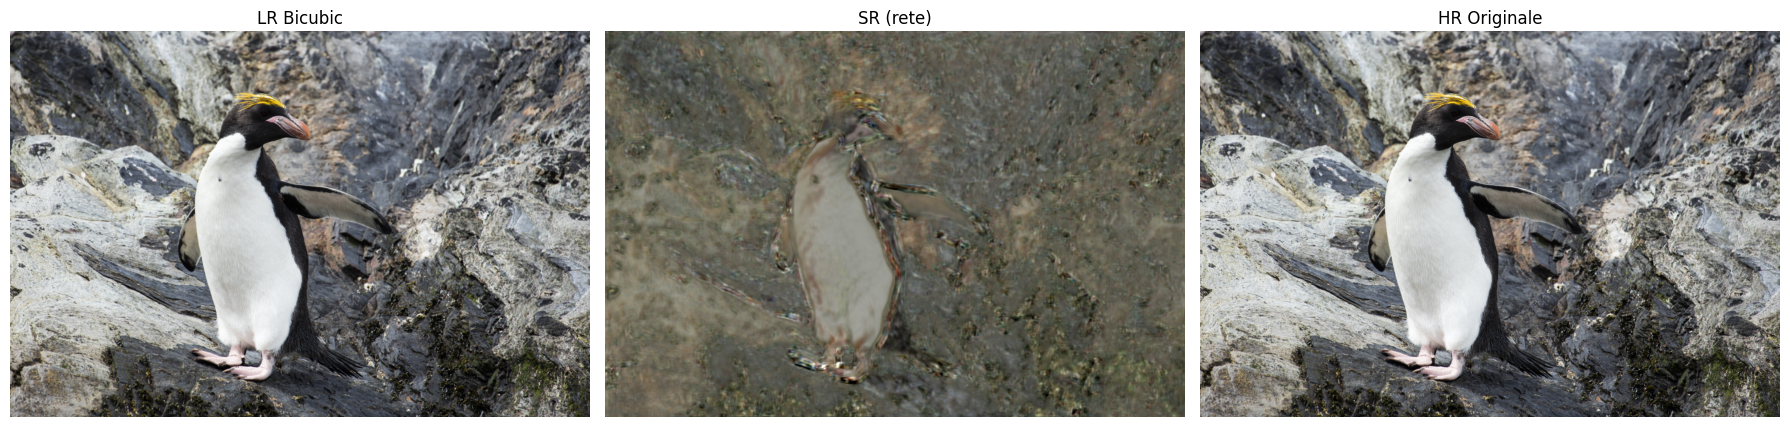

In [ ]:
import torchvision.transforms.functional as TF

# 1. Carica l'immagine LR

lr_batch, hr_batch = next(iter(valid_loader))

lr_batch = lr_batch.to(device)
hr_batch = hr_batch.to(device)

model.eval()

with torch.no_grad():
    output = model(lr_batch)

lr_img = TF.to_pil_image(lr_batch.squeeze(0).clamp(0, 1))
sr_img = TF.to_pil_image(output.squeeze(0).clamp(0, 1))
hr_img = TF.to_pil_image(hr_batch.squeeze(0).clamp(0, 1))

# 5. Visualizzazione
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(lr_img)
axes[0].set_title('LR Bicubic')
axes[0].axis('off') 

axes[1].imshow(sr_img)
axes[1].set_title('SR (rete)')
axes[1].axis('off')

axes[2].imshow(hr_img)
axes[2].set_title('HR Originale')
axes[2].axis('off')

plt.tight_layout()
plt.savefig(SAVE_PATH.replace('.pth', '_comparison.png'), bbox_inches='tight', dpi=150)
plt.show()
